# 03. SFT-обучение (QLoRA) на T4

Дообучаем Qwen2.5-3B-Instruct на данных для бытовых вопросов «Дом и квартира».

**Требования:** Google Colab, GPU T4. На T4 нет bf16 — везде используем **fp16**
(в отличие от A100/L4, где лучше bf16).

**Режимы запуска:**
- `SMOKE_TEST = True` (по умолчанию) — 10 шагов на мини-датасете: проверка, что
  пайплайн живой, лосс логируется, чекпоинты пишутся. Запускается ~2 минуты.
- `SMOKE_TEST = False` — полное обучение на `data/sft_train.jsonl`.

Если `data/sft_train.jsonl` не существует, ноутбук создаёт **демо-датасет из 8
примеров** — только для smoke-теста пайплайна, обучать на нём всерьёз нельзя.

In [1]:
SMOKE_TEST = False   # True: 10 шагов для проверки пайплайна; False: полное обучение

# Клонируем проект (повторный запуск в той же сессии не будет клонировать заново;
# чтобы получить свежую версию: %cd /content && !rm -rf lm-hw и запустить ячейку снова)
import os

if not os.path.exists("lm-hw"):
    !git clone https://github.com/maria-igntv/lm-hw.git
%cd lm-hw

!pip install -q -U transformers datasets trl peft bitsandbytes accelerate wandb

import torch
print(torch.__version__, torch.cuda.get_device_name(0))
assert torch.cuda.is_available(), "Нужен GPU: Runtime -> Change runtime type -> T4"

Cloning into 'lm-hw'...
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 64 (delta 23), reused 57 (delta 16), pack-reused 0 (from 0)
Receiving objects: 100% (64/64), 616.54 KiB | 2.31 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/lm-hw
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
2.11.0+cu130 Tesla T4


In [2]:
# wandb: раскомментируйте и вставьте ключ для полного обучения.
# Без ключа логи пойдут в offline-режим (сохранятся локально, в облако не уйдут).
os.environ["WANDB_PROJECT"] = "lm-hw-sft"
# import wandb; wandb.login(key="<YOUR_KEY>")
os.environ.setdefault("WANDB_MODE", "offline")

MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"
SEED = 42

In [3]:
# Данные SFT: ожидаем data/sft_train.jsonl и data/sft_val.jsonl в формате
# {"messages": [{"role": "system", ...}, {"role": "user", ...}, {"role": "assistant", ...}]}
import json
from datasets import Dataset

DEMO_MESSAGES = [
    {"messages": [
        {"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, когда нужно вызвать специалиста."},
        {"role": "user", "content": "Течёт батарея, что нужно делать?"},
        {"role": "assistant", "content": "Порядок действий при течи батареи:\n\n1. Подставьте ёмкость и накройте место течи тряпкой, чтобы вода не лилась на пол.\n2. Перекройте запорные краны на подводке к батарее (если они есть).\n3. Если кранов нет или течёт сам стояк — срочно звоните в управляющую компанию или аварийную службу (112): перекрытие стояка — их зона ответственности.\n\nВНИМАНИЕ: не пытайтесь устранять течь на работающей системе под давлением — можно получить ожог горячей водой. Самостоятельный ремонт радиатора допустим только после отключения и остывания, и лучше доверить его сантехнику."}]},
    {"messages": [
        {"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, когда нужно вызвать специалиста."},
        {"role": "user", "content": "В кухне пахнет газом, что делать?"},
        {"role": "assistant", "content": "При запахе газа действовать нужно немедленно:\n\n1. НЕ включайте и не выключайте электроприборы и свет — искра может вызвать взрыв.\n2. Перекройте кран подачи газа к плите.\n3. Откройте окна и покиньте помещение.\n4. С улицы позвоните в аварийную газовую службу: 104 или 112.\n\nВозвращаться можно только после проверки помещения специалистом. ОСТОРОЖНО: утечка газа — риск взрыва и отравления, самостоятельно искать место утечки нельзя."}]},
    {"messages": [
        {"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, когда нужно вызвать специалиста."},
        {"role": "user", "content": "Дверь цепляется за напольное покрытие, как исправить?"},
        {"role": "assistant", "content": "Чаще всего дверь цепляет покрытие из-за просевших петель или вспучившегося ламината.\n\n1. Осмотрите зазор: если он равномерно маленький по низу — проблема в петлях, если в одном месте — в покрытии.\n2. Петли: приоткройте дверь, ослабьте нижний винт ближней к проблемному краю петли, слегка приподнимите полотно и затяните винт.\n3. Покрытие: проверьте стыки ламината, при вспучивании снимите плинтус и дайте полотнам место для температурного расширения.\n\nЕсли дверь деревянная и задевает постоянно — циклёвой или рубанок снимите 1–2 мм с нижнего края, затем подкрасьте торец."}]},
    {"messages": [
        {"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, когда нужно вызвать специалиста."},
        {"role": "user", "content": "Чем отмыть жир с кухонных шкафов без следов?"},
        {"role": "assistant", "content": "Для кухонных шкафов лучше всего работает тёплый раствор соды (2 ст. ложки на 0,5 л воды) или средство для мытья посуды.\n\n1. Смочите мягкую тряпку, отожмите и протрите фасады по направлению волокон/текстуры.\n2. Застарелый жир: нанесите кашицу из соды на 10–15 минут, затем смойте.\n3. Протрите насухо чистой тканью — иначе останутся разводы.\n\nДля глянцевых и пластиковых фасадов не используйте абразивы и спирт в высокой концентрации — останутся царапины и матовые пятна."}]},
    {"messages": [
        {"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, когда нужно вызвать специалиста."},
        {"role": "user", "content": "Как поменять розетку самому?"},
        {"role": "assistant", "content": "Заменить розетку можно самостоятельно, но работа связана с электричеством.\n\n1. Обесточьте линию: выключите соответствующий автомат в щитке.\n2. Проверьте отсутствие напряжения индикаторной отвёрткой в самой розетке.\n3. Открутите крышку, ослабьте распорные лапки, вытяните механизм.\n4. Отсоедините провода и подключите к новой розетке (фаза/ноль — к силовым контактам, заземление — к «усам»).\n5. Зафиксируйте механизм, установите крышку, включите автомат и проверьте розетку.\n\nВНИМАНИЕ: риск поражения током. Если провода алюминиевые, старые или непонятно, какой автомат отключает линию, — вызывайте электрика. Работать под напряжением нельзя."}]},
    {"messages": [
        {"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, когда нужно вызвать специалиста."},
        {"role": "user", "content": "Забилась канализация в раковине, чем прочистить?"},
        {"role": "assistant", "content": "Порядок прочистки раковины — от простого к сложному:\n\n1. Кипяток и средство для труб: залейте на 15–20 минут, затем промойте горячей водой.\n2. Вантуз: закройте перелил мокрой тряпкой, прокачайте слив 15–20 раз.\n3. Разберите сифон под раковиной: подставьте таз, открутите колбу, очистите от налёта и волос, соберите обратно, проверив прокладки.\n\nХимические средства со щёлочью используйте строго в перчатках и не смешивайте разные составы. Если вода стоит в нескольких точках квартиры сразу — засор в стояке, звоните в управляющую компанию: самостоятельно такие засоры не прочищают."}]},
    {"messages": [
        {"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, когда нужно вызвать специалиста."},
        {"role": "user", "content": "Как убрать царапину с ламината?"},
        {"role": "assistant", "content": "Способ зависит от глубины царапины:\n\n1. Малозаметные: восковый карандаш под цвет ламината — закрасьте царапину вдоль, отполируйте мягкой тканью.\n2. Глубокие: шпатлёвка/ремонтная паста для ламината, после высыхания — защитный слой лака.\n3. Повреждена доска целиком: проще заменить панель — разберите пол от ближайшей стены до повреждения и соберите заново.\n\nСохраните запасную пачку ламината при укладке — замена отдельных панелей без разборки всего пола возможна только для клеевого способа, а для замкового потребуется частичный разбор."}]},
    {"messages": [
        {"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, когда нужно вызвать специалиста."},
        {"role": "user", "content": "Сквозит из-под входной двери, чем утеплить?"},
        {"role": "assistant", "content": "Сквозняк из-под двери убирается в два шага:\n\n1. Уплотнитель по периметру: самоклеящаяся резиновая лента по размеру зазора (2–5 мм). Наклейте на дверную коробку, предварительно обезжирив поверхность.\n2. Щель внизу: дверной щётка-уплотнитель или порог с автоматическим уплотнителем. Самое простое — планка со щёткой на нижний торец двери.\n\nЕсли дверь старая и продувает по всему полотну — поможет только замена или капитальная регулировка. Заодно проверьте, не промерзает ли дверная коробка: иней по краям зимой означает проблемы с утеплением откосов."}]},
]

def load_jsonl(path):
    return [json.loads(l) for l in open(path, encoding="utf-8")]

have_data = os.path.exists("data/sft_train.jsonl") and os.path.exists("data/sft_val.jsonl")
if have_data:
    train_raw = load_jsonl("data/sft_train.jsonl")
    val_raw = load_jsonl("data/sft_val.jsonl")
    print(f"Загружены данные: train={len(train_raw)}, val={len(val_raw)}")
else:
    train_raw = DEMO_MESSAGES[:6]
    val_raw = DEMO_MESSAGES[6:]
    print("! data/sft_train.jsonl не найден — используется ДЕМО-датасет (8 примеров).")
    print("! Он годится только для smoke-теста пайплайна, НЕ для обучения.")

# В smoke-режиме берём маленькие выборки, чтобы прогон был быстрым
if SMOKE_TEST:
    train_raw = train_raw[:8]
    val_raw = val_raw[:2]

train_ds = Dataset.from_list(train_raw)
val_ds = Dataset.from_list(val_raw)
print(train_ds)

Загружены данные: train=618, val=32
Dataset({
    features: ['messages'],
    num_rows: 618
})


In [4]:
# Модель в 4-bit + LoRA
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,   # T4 не поддерживает bf16!
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.float16,
)
model = prepare_model_for_kbit_training(model)
model.config.use_cache = False  # конфликтует с gradient checkpointing

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora_config)
print("Model dtype:", model.dtype)
model.print_trainable_parameters()

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model dtype: torch.float32
trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


In [5]:
# Формат данных для trl 1.x: prompt (system + user) + completion (assistant).
# SFTTrainer сам применит chat template и замаскирует токены промпта при
# completion_only_loss=True — это современная замена DataCollatorForCompletionOnlyLM,
# который удалён из trl 1.x.
def to_prompt_completion(example):
    msgs = example["messages"]
    return {"prompt": msgs[:-1], "completion": [msgs[-1]]}

train_pc = train_ds.map(to_prompt_completion, remove_columns=train_ds.column_names)
val_pc = val_ds.map(to_prompt_completion, remove_columns=val_ds.column_names)
print("Пример prompt:", json.dumps(train_pc[0]["prompt"], ensure_ascii=False)[:200])

Map:   0%|          | 0/618 [00:00<?, ? examples/s]

Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Пример prompt: [{"role": "system", "content": "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, протечки, нагрузки н


In [6]:
# Конфигурация обучения (API trl 1.x: max_length, completion_only_loss, warmup_steps)
from trl import SFTConfig, SFTTrainer

eval_every = 5 if SMOKE_TEST else 25   # в smoke-режиме (10 шагов) чаще

training_args = SFTConfig(
    output_dir="results/sft_checkpoints",
    seed=SEED,
    # Данные
    max_length=1024,
    completion_only_loss=True,        # лосс только по ответу ассистента
    packing=False,
    # Оптимизация (под T4 16GB)
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,     # эффективный batch = 16
    gradient_checkpointing=True,
    optim="paged_adamw_32bit",
    fp16=False,
    bf16=False,
    # T4: только fp16
    # Гиперпараметры
    num_train_epochs=3,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=3,                     # ~3% шагов полного прогона
    weight_decay=0.01,
    # Мониторинг и чекпоинты
    logging_steps=5,
    eval_strategy="steps",
    eval_steps=eval_every,
    save_strategy="steps",
    save_steps=eval_every,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="wandb",
    # Smoke-режим: короткий прогон
    max_steps=10 if SMOKE_TEST else -1,
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_pc,
    eval_dataset=val_pc,
    processing_class=tokenizer,
)

# ПРОВЕРКА МАСКИРОВАНИЯ (обязательный sanity check!):
# labels == -100 на токенах промпта, реальные метки — только на ответе ассистента
batch = next(iter(trainer.get_train_dataloader()))
labels = batch["labels"][0]
n_masked = (labels == -100).sum().item()
n_supervised = (labels != -100).sum().item()
print(f"Токенов в примере: {labels.numel()}, замаскировано (промпт): {n_masked}, "
      f"с лоссом (ответ ассистента): {n_supervised}")
assert 0 < n_supervised < labels.numel(), \
    "Маскировка сломана: лосс идёт по всему тексту или ни по чему"
print("Маскирование работает корректно")

#  ЗАПУСК ОБУЧЕНИЯ
train_result = trainer.train()
print(train_result.metrics)

[INFO] Running in WANDB offline mode


Tokenizing train dataset:   0%|          | 0/618 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/618 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/618 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/618 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/32 [00:00<?, ? examples/s]

... (4 outputs left out)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,1.769798,1.779652,1.820933,0.589757,167840.000000
50,1.565561,1.728249,1.579765,0.600482,333252.000000
75,1.535972,1.695597,1.593267,0.607613,500935.000000
100,1.370552,1.716077,1.448318,0.606749,666581.000000
117,1.373189,1.714920,1.453973,0.606620,778512.000000


wandb: WARNING URL not available in offline run
wandb: WARNING URL not available in offline run
wandb: WARNING URL not available in offline run
wandb: WARNING URL not available in offline run
wandb: WARNING URL not available in offline run


{'train_runtime': 2686.4821, 'train_samples_per_second': 0.69, 'train_steps_per_second': 0.044, 'total_flos': 1.3988915332743168e+16, 'train_loss': 1.5755074166844034, 'epoch': 3.0}


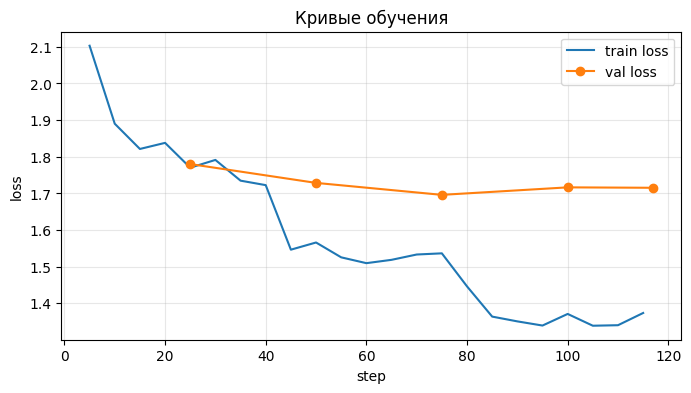

Лучший чекпоинт: results/sft_checkpoints/checkpoint-75
Лучший eval_loss: 1.6956


In [7]:
# Кривые обучения -> PNG (в отчёт) + таблица логов
import matplotlib.pyplot as plt

logs = [l for l in trainer.state.log_history if "loss" in l or "eval_loss" in l]
train_pts = [(l["step"], l["loss"]) for l in logs if "loss" in l]
val_pts = [(l["step"], l["eval_loss"]) for l in logs if "eval_loss" in l]

plt.figure(figsize=(8, 4))
if train_pts:
    plt.plot(*zip(*train_pts), label="train loss")
if val_pts:
    plt.plot(*zip(*val_pts), label="val loss", marker="o")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Кривые обучения" + (" (SMOKE TEST)" if SMOKE_TEST else ""))
os.makedirs("results", exist_ok=True)
plt.savefig("results/sft_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# Лучший чекпоинт (по min eval_loss)
print("Лучший чекпоинт:", trainer.state.best_model_checkpoint)

if trainer.state.best_metric is not None:
    print(f"Лучший eval_loss: {trainer.state.best_metric:.4f}")
else:
    print("Лучший eval_loss: N/A (обучение ещё не запущено)")

In [8]:
# Сохранение LoRA-адаптера (safetensors)
model.config.use_cache = True
ADAPTER_DIR = "results/sft_adapter"
trainer.save_model(ADAPTER_DIR)          # адаптер + конфиг LoRA
tokenizer.save_pretrained(ADAPTER_DIR)
print("Адаптер сохранён:", ADAPTER_DIR)
print(os.listdir(ADAPTER_DIR))

# Опционально: загрузить на Hugging Face Hub (для артефактов)
# model.push_to_hub("<username>/qwen2.5-3b-home-sft")
# tokenizer.push_to_hub("<username>/qwen2.5-3b-home-sft")

Адаптер сохранён: results/sft_adapter
['adapter_config.json', 'adapter_model.safetensors', 'training_args.bin', 'chat_template.jinja', 'README.md', 'tokenizer_config.json', 'tokenizer.json']


In [9]:
# Быстрая качественная проверка: те же 2 вопроса, что в 01_baseline
SYSTEM_PROMPT = (
    "Ты — помощник по бытовым вопросам дома и квартиры. Отвечай на русском "
    "языке, кратко и по делу. Если вопрос связан с опасностью (газ, электричество, "
    "протечки, нагрузки на конструкции), обязательно предупреди о рисках и укажи, "
    "когда нужно вызвать специалиста."
)
GEN_KWARGS = dict(max_new_tokens=512, temperature=0.7, top_p=0.9,
                  do_sample=True, repetition_penalty=1.05)

model.eval()
@torch.no_grad()
def generate_answer(question: str) -> str:
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]
    # return_dict=True: отдаёт input_ids И attention_mask
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    out = model.generate(**inputs, **GEN_KWARGS)
    prompt_len = inputs["input_ids"].shape[1]
    return tokenizer.decode(out[0][prompt_len:], skip_special_tokens=True)

for q in ["Течёт батарея, что нужно делать?",
          "Как поменять розетку самому?"]:
    print("=" * 80)
    print("ВОПРОС:", q)
    print("ОТВЕТ:", generate_answer(q))

ВОПРОС: Течёт батарея, что нужно делать?
ОТВЕТ: Первое, что стоит сделать — отключите краны подачи и возврата воды: это остановит течь немедленно и снизит риск залива соседей. Затем откройте вентканал для высыхания. Самостоятельно перекрывать батарею при высоком давлении или слабых навыках — не лучшая идея: есть риск порвать саму трубу, а при этом она продолжает капать на пол. Соберитесь с силами и вызовите сантехника из УК или мастеров по сантехнике — обычно они приезжают бесплатно при утечке в доме. Важно, чтобы он работал по гарантии: если батарея уже старая и слабо защищена, ремонт может стоить дороже новой резьбовой магеллановой гайки. Не откладывайте, если течёт батарея на полу — вода со временем затопляет соседей и соседку.
ВОПРОС: Как поменять розетку самому?
ОТВЕТ: Работать можно только в отключённом автомате, поэтому вначале перекройте его и проверьте индикатором или прибором ночного контроля. Затем снимите старую розетку: сначала выньте из гнезда удлинитель и выкрутите самор

## Как читать кривые обучения (диагностика)

| Симптом на графике | Диагноз | Что делать |
|---|---|---|
| train loss не падает | lr слишком мал/велик или данные мусор | lr 1e-4…3e-4; проверить данные |
| train падает, val растёт | переобучение | меньше эпох, ранний стоп (лучший чекпоинт уже выбирается по val) |
| loss скачет вверх | расхождение, слишком большой lr | снизить lr, увеличить grad accumulation |
| Модель повторяет текст вопроса | маскировка лосса не работает | проверить assert маскировки выше |
| Ответы стали шаблонными | переобучение на однообразной синтетике | разнообразить данные, меньше эпох |

## Дальше

1. После генерации данных (`02_data_gen`) вернуться сюда: `SMOKE_TEST = False`,
   ввести wandb-ключ и запустить полное обучение.
2. Полный прогон на 500–1500 примеров на T4: ~30–90 минут на 2–3 эпохи.
3. Затем ноутбук 04: оценка до/после на фиксированном eval-сете
   (автопроверки + судья) с теми же параметрами генерации.

Примечание: локальная отладка этого же пайплайна (trl 1.x, prompt/completion,
проверка маскирования) — `script/debug_sft.py`, прогоняется на Mac (MPS) с
Qwen2.5-0.5B без квантования.